# Appendix — Second pair: KO / PEP (test of the Phase 1–2 pipeline)

**This appendix does not replace INTC/AMD, which remains the pair of the project.** It has its own counters (9 IS backtests, 1 OOS access planned).

Pre-registered in `EXPERIMENTS.md` (2026-10-10 17:03 CEST) **before downloading or looking at any KO/PEP price**. Disclosure: the pair was added *after* seeing the negative INTC/AMD result, to test the pipeline on a pair with an economic reason to be cointegrated; KO/PEP was chosen because the brief calls it "the classic textbook pair", not for its results. The user had no information on the recent performance of the two companies.

Design identical to the main project: A = KO, B = PEP; OLS on log prices on the IS only; ADF and Engle–Granger on the IS; main configuration e = 2.0, L = 60, exit at 0, `shift(1)`, 5 bp/leg, rf = 0; 3×3 grid on the IS as a sensitivity measure; one OOS run of the main configuration with β frozen. Split by the same 70% rule: **2010-01-01** (IS = dates < 2010-01-01).

In [1]:
import logging
from datetime import date

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, display
from plotly.subplots import make_subplots

from pairs.backtest import run_strategy
from pairs.data import load_pair
from pairs.metrics import performance_summary
from pairs.plotting import DERIVED_COLOR, apply_style, save_figure
from pairs.spread import BETA_WARNING_THRESHOLD, compute_spread, fit_hedge_ratio, stationarity_tests

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
for noisy in ("kaleido", "choreographer"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

# Pre-registered (EXPERIMENTS.md, 2026-10-10 17:03 and 17:08 CEST). Do not edit.
A, B = "KO", "PEP"
SPLIT = date(2010, 1, 1)
ENTRIES, LOOKBACKS = [1.5, 2.0, 2.5], [20, 60, 120]
MAIN_ENTRY, MAIN_LOOKBACK, COST_BPS = 2.0, 60, 5.0
COLORS = {A: "#2a78d6", B: "#eb6834"}  # categorical slots 1 and 2

In [2]:
prices_is = load_pair(end=SPLIT, ticker_a=A, ticker_b=B)
assert prices_is.index.max() < pd.Timestamp(SPLIT), "OOS date leaked"
assert len(prices_is) == 9485, "must match the IS day count in EXPERIMENTS.md"
print(
    f"IS: {len(prices_is)} common days, {prices_is.index[0].date()} -> {prices_is.index[-1].date()}"
)

WARNING pairs.data: Alignment dropped 2599 rows present in only one series


INFO pairs.data: Loaded KO/PEP: 9485 common days, 1972-06-01 -> 2009-12-31 (end=2010-01-01, exclusive)


IS: 9485 common days, 1972-06-01 -> 2009-12-31


## 1. Prices (log scale) and the KO/PEP ratio — in-sample only

INFO pairs.plotting: Saved figure appx_a_kopep_prices_ratio_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


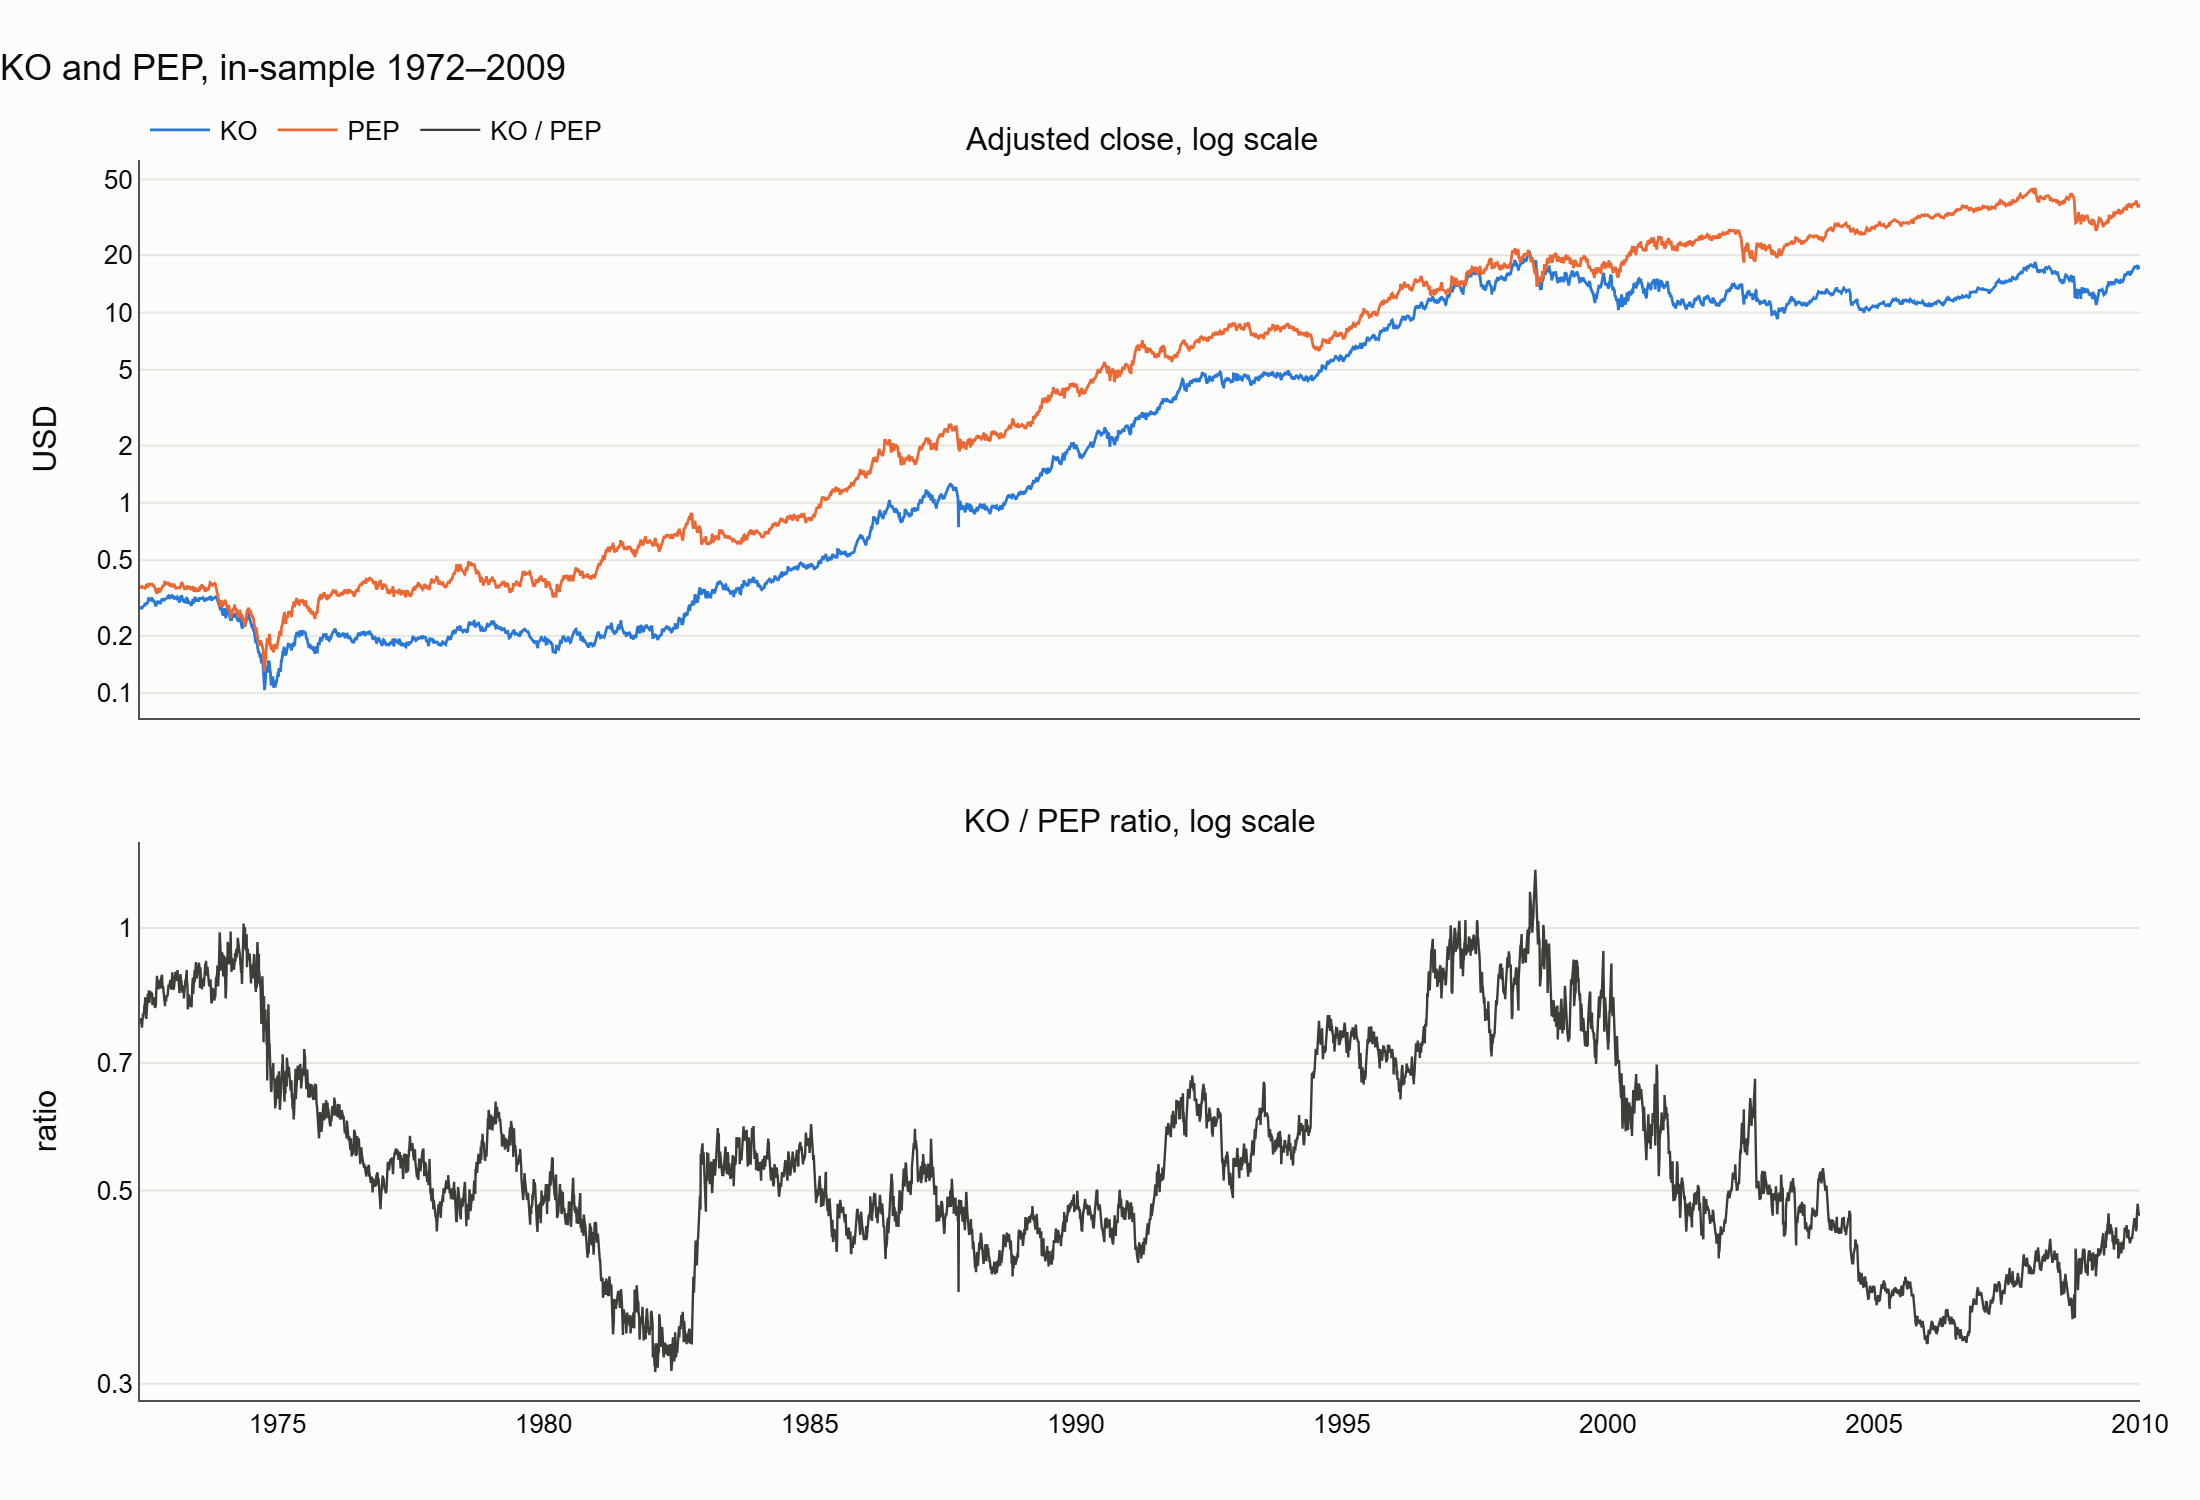

In [3]:
fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.10,
    subplot_titles=("Adjusted close, log scale", "KO / PEP ratio, log scale"),
)
for t in (A, B):
    fig.add_trace(
        go.Scatter(
            x=prices_is.index, y=prices_is[t], name=t, line={"color": COLORS[t], "width": 1.4}
        ),
        row=1,
        col=1,
    )
ratio_is = prices_is[A] / prices_is[B]
fig.add_trace(
    go.Scatter(
        x=ratio_is.index, y=ratio_is, name="KO / PEP", line={"color": DERIVED_COLOR, "width": 1.2}
    ),
    row=2,
    col=1,
)
apply_style(fig, "KO and PEP, in-sample 1972–2009")
fig.update_yaxes(
    type="log", tickvals=[0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100], title_text="USD", row=1, col=1
)
fig.update_yaxes(
    type="log",
    tickvals=[0.1, 0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 5],
    title_text="ratio",
    row=2,
    col=1,
)
_, png = save_figure(fig, "appx_a_kopep_prices_ratio_is", height=750)
display(Image(filename=png))

## 2. Hedge regression and stationarity of the IS spread

In [4]:
fit = fit_hedge_ratio(prices_is, end=SPLIT, ticker_a=A, ticker_b=B)
if fit.beta <= 0:
    print(f"PROBLEM: beta = {fit.beta:.4f} <= 0, the PEP leg is not a hedge.")
elif fit.beta <= BETA_WARNING_THRESHOLD:
    print(f"PROBLEM: beta = {fit.beta:.4f} is close to zero, the PEP leg barely hedges KO.")
else:
    print(f"beta = {fit.beta:.4f} > {BETA_WARNING_THRESHOLD}: PEP acts as a hedge for KO.")
display(
    pd.DataFrame(
        {"value": [fit.alpha, fit.beta, fit.r_squared, fit.n_obs, fit.first_date, fit.last_date]},
        index=["alpha", "beta", "R²", "n_obs", "first date", "last date"],
    )
)
st = stationarity_tests(prices_is, beta=fit.beta, end=SPLIT, ticker_a=A, ticker_b=B)
display(
    pd.DataFrame(
        {"statistic": [st.adf_stat, st.eg_stat], "p_value": [st.adf_pvalue, st.eg_pvalue]},
        index=[f"ADF on spread (lags={st.adf_lags})", "Engle–Granger"],
    ).round(4)
)
print(
    f"Descriptive only: AR(1) coefficient b = {st.ar1_coef:.5f}, implied half-life ≈ "
    f"{st.half_life_days:,.0f} trading days. The correct significance test for b is the ADF above."
)

INFO pairs.spread: Hedge fit (log prices) KO ~ PEP on 1972-06-01..2009-12-31: alpha=-0.5909 beta=0.9805 R2=0.9753


beta = 0.9805 > 0.1: PEP acts as a hedge for KO.


,value
alpha,-0.59093
beta,0.980525
R²,0.97532
n_obs,9485
first date,1972-06-01
last date,2009-12-31


,statistic,p_value
ADF on spread (lags=16),-2.1561,0.2226
Engle–Granger,-2.1559,0.4472


Descriptive only: AR(1) coefficient b = -0.00180, implied half-life ≈ 386 trading days. The correct significance test for b is the ADF above.


INFO pairs.plotting: Saved figure appx_b_kopep_spread_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


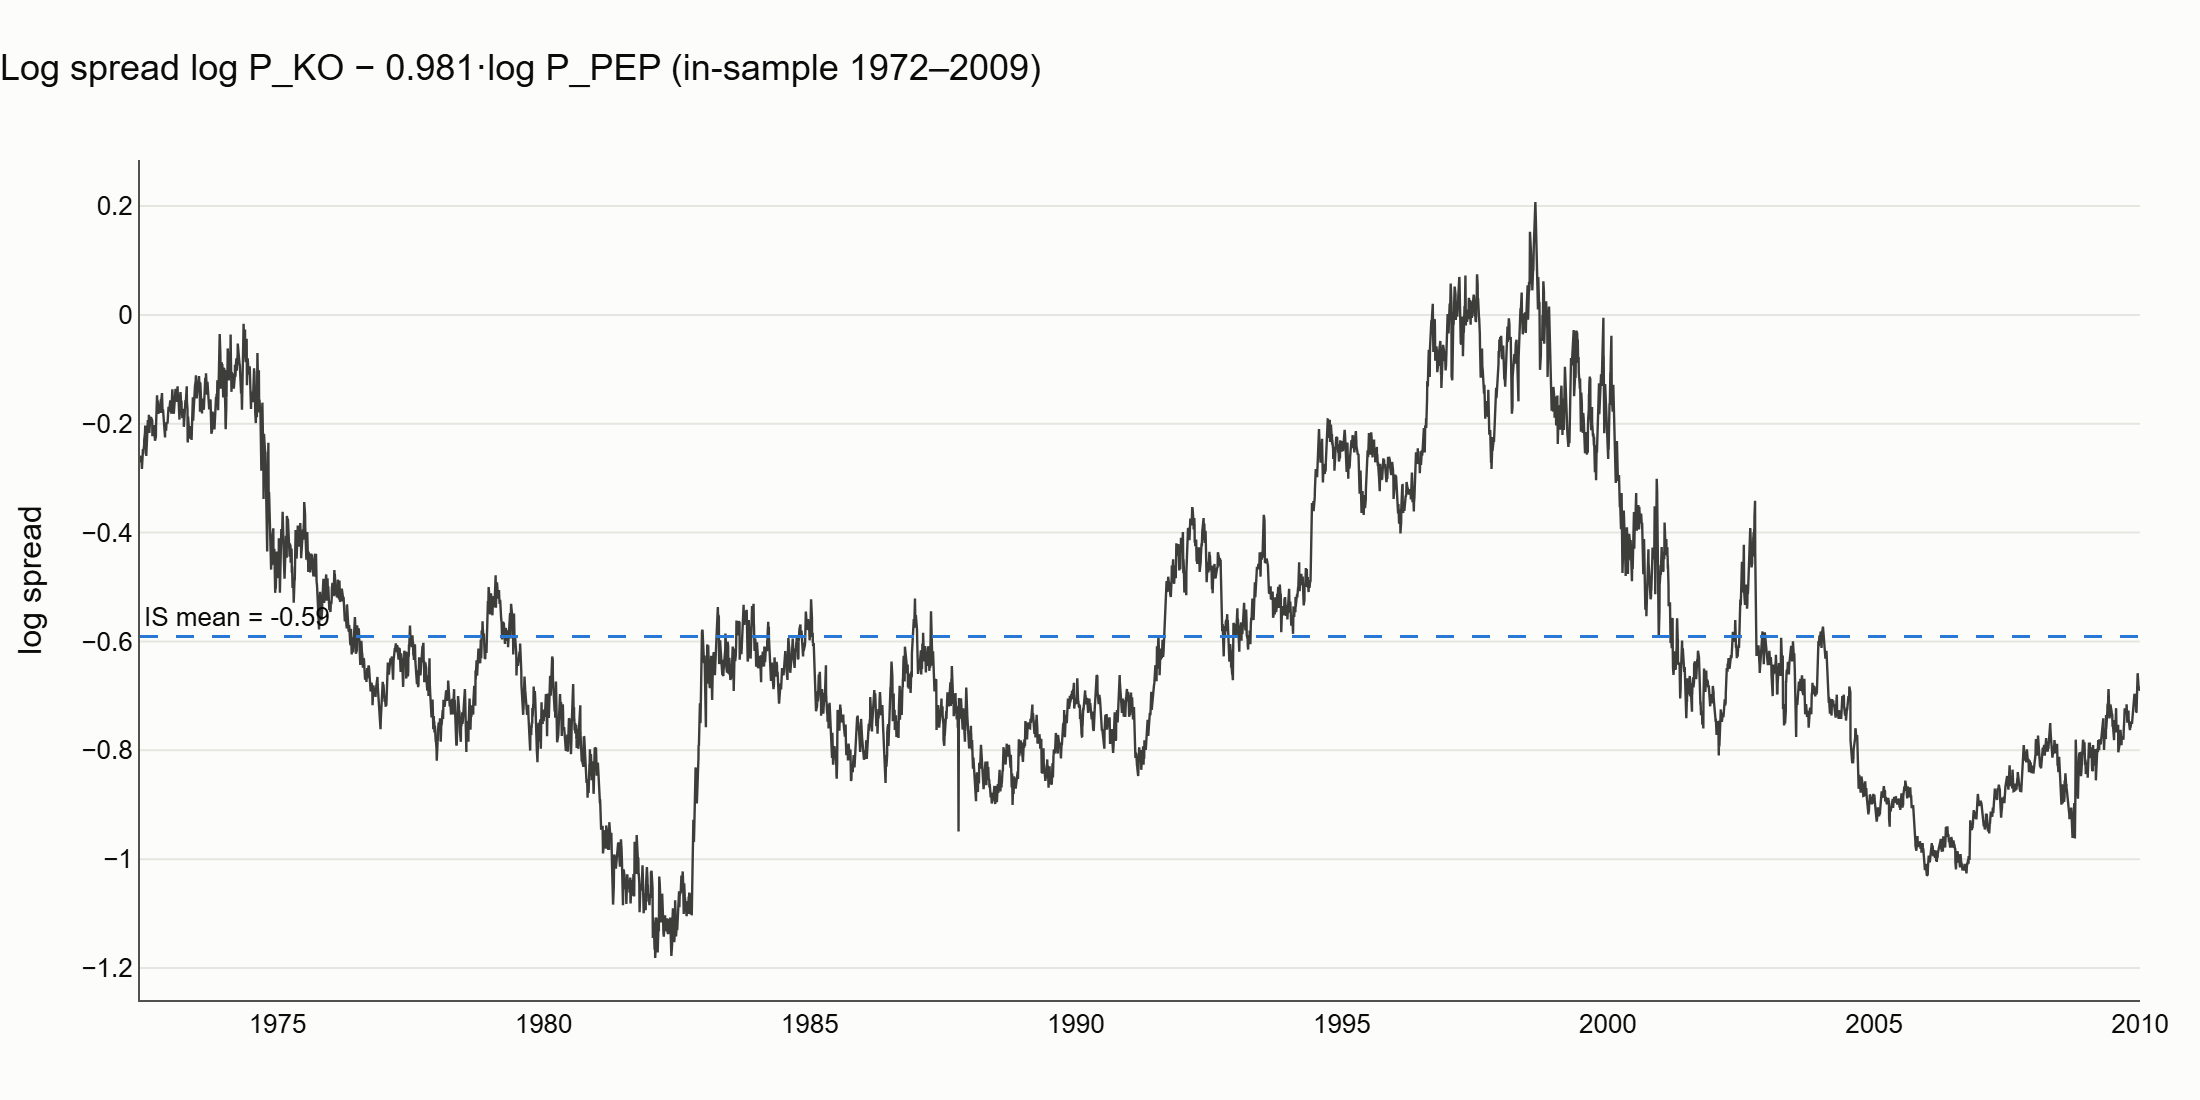

In [5]:
spread = compute_spread(prices_is, fit.beta, A, B)
assert abs(spread.mean() - fit.alpha) < 1e-8
fig = go.Figure()
fig.add_trace(
    go.Scatter(x=spread.index, y=spread, name="spread", line={"color": DERIVED_COLOR, "width": 1.2})
)
fig.add_hline(
    y=spread.mean(),
    line={"color": "#2a78d6", "width": 1.5, "dash": "dash"},
    annotation_text=f"IS mean = {spread.mean():.2f}",
    annotation_position="top left",
)
apply_style(fig, f"Log spread log P_KO − {fit.beta:.3f}·log P_PEP (in-sample 1972–2009)")
fig.update_layout(showlegend=False)
fig.update_yaxes(title_text="log spread")
_, png = save_figure(fig, "appx_b_kopep_spread_is")
display(Image(filename=png))

## 3. Full pre-registered IS grid (9 appendix backtests) and the main configuration

Common evaluation window from the first day with an L = 120 z-score, as in Phase 2. The grid measures sensitivity; the main configuration (e = 2.0, L = 60) was fixed a priori.

INFO pairs.backtest: log e=1.5 L=20 lag=1: 530 trades, 1972-11-20..2009-12-31


INFO pairs.backtest: log e=1.5 L=60 lag=1: 229 trades, 1972-11-20..2009-12-31


INFO pairs.backtest: log e=1.5 L=120 lag=1: 136 trades, 1972-11-20..2009-12-31


INFO pairs.backtest: log e=2.0 L=20 lag=1: 351 trades, 1972-11-20..2009-12-31


INFO pairs.backtest: log e=2.0 L=60 lag=1: 166 trades, 1972-11-20..2009-12-31


...

INFO pairs.backtest: log e=2.5 L=20 lag=1: 151 trades, 1972-11-20..2009-12-31


INFO pairs.backtest: log e=2.5 L=60 lag=1: 101 trades, 1972-11-20..2009-12-31


INFO pairs.backtest: log e=2.5 L=120 lag=1: 63 trades, 1972-11-20..2009-12-31


Evaluation window: 1972-11-20 -> 2009-12-31


INFO pairs.plotting: Saved figure appx_c_kopep_sharpe_heatmap_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


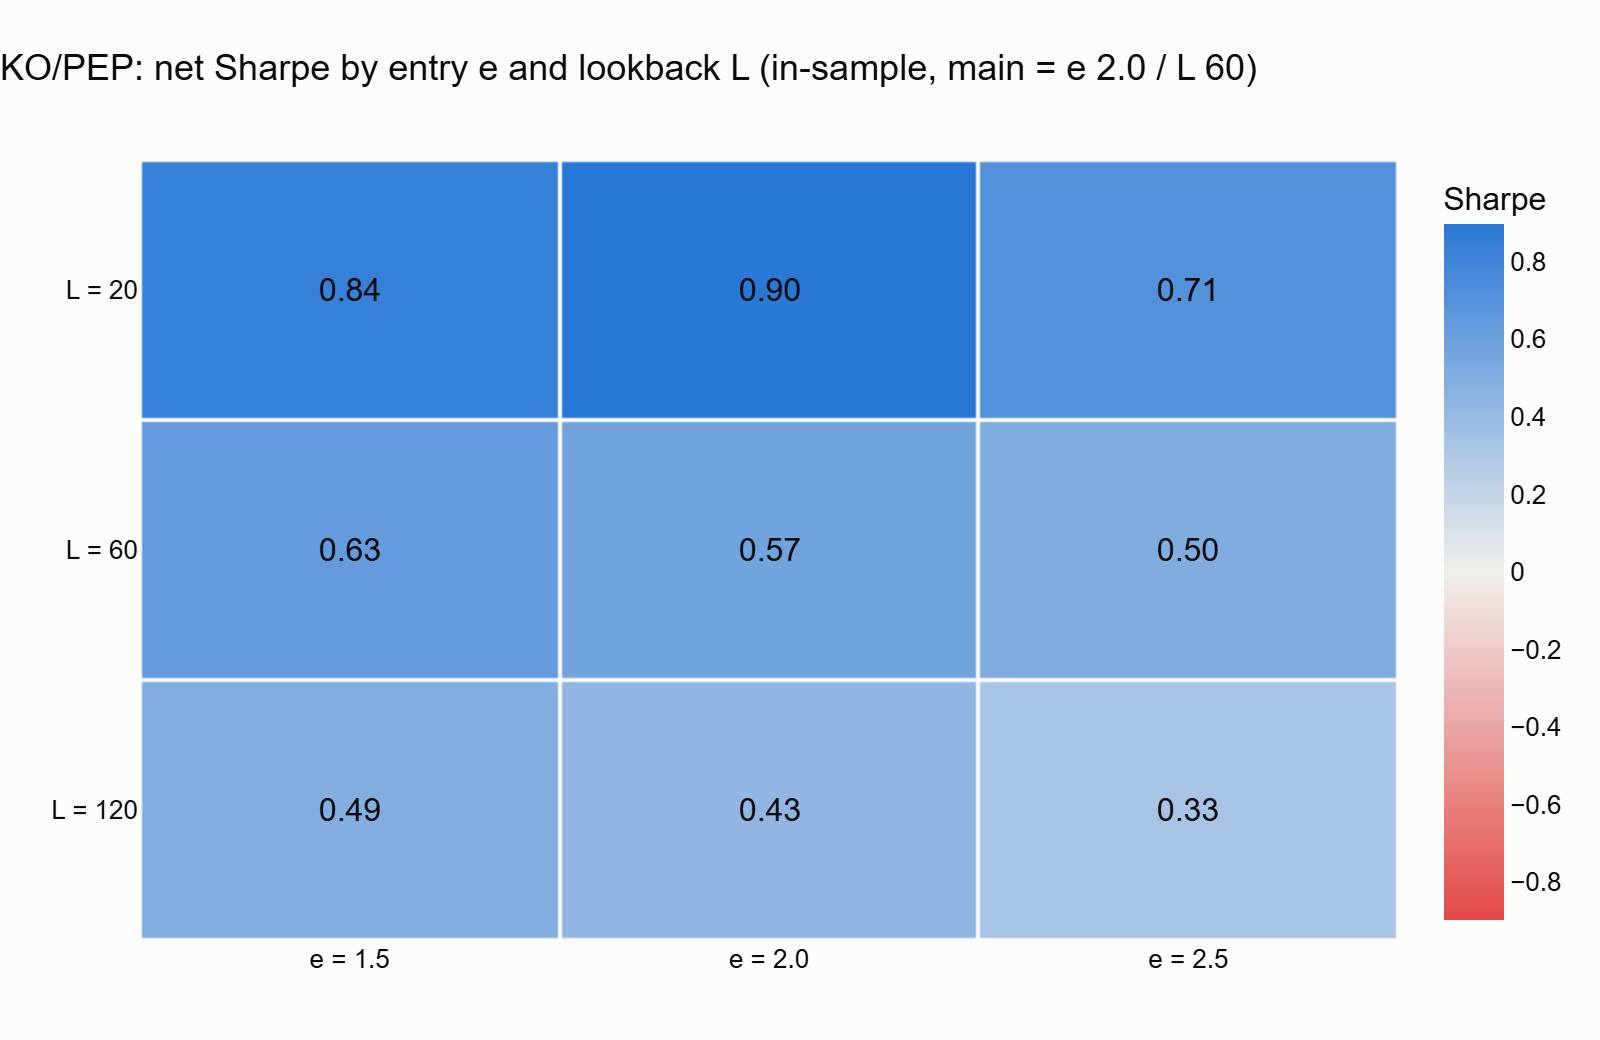

In [6]:
trade_from = spread.index[max(LOOKBACKS) - 1].date()
runs = {
    (e, L): run_strategy(
        prices_is,
        fit.beta,
        entry=e,
        lookback=L,
        end=SPLIT,
        trade_from=trade_from,
        cost_bps=COST_BPS,
        ticker_a=A,
        ticker_b=B,
    )
    for e in ENTRIES
    for L in LOOKBACKS
}
assert len(runs) == 9, "pre-registered number of appendix IS backtests"
grid = pd.DataFrame(
    [
        {"entry_e": e, "lookback_L": L, **performance_summary(r.daily, r.trades)}
        for (e, L), r in runs.items()
    ]
)
print(f"Evaluation window: {trade_from} -> {spread.index[-1].date()}")

mat = grid.pivot(index="lookback_L", columns="entry_e", values="sharpe_net")
zmax = float(np.nanmax(np.abs(mat.to_numpy())))
fig = go.Figure(
    go.Heatmap(
        z=mat.to_numpy(),
        x=[f"e = {e}" for e in mat.columns],
        y=[f"L = {L}" for L in mat.index],
        colorscale=[[0.0, "#e34948"], [0.5, "#f0efec"], [1.0, "#2a78d6"]],
        zmin=-zmax,
        zmid=0,
        zmax=zmax,
        text=np.vectorize(lambda v: f"{v:.2f}")(mat.to_numpy()),
        texttemplate="%{text}",
        textfont={"size": 16, "color": "#0b0b0b"},
        colorbar={"title": "Sharpe"},
        xgap=2,
        ygap=2,
    )
)
apply_style(fig, "KO/PEP: net Sharpe by entry e and lookback L (in-sample, main = e 2.0 / L 60)")
fig.update_xaxes(showline=False)
fig.update_yaxes(showline=False, gridcolor="rgba(0,0,0,0)", autorange="reversed")
fig.update_layout(hovermode="closest")
_, png = save_figure(fig, "appx_c_kopep_sharpe_heatmap_is", width=800, height=520)
display(Image(filename=png))

INFO pairs.plotting: Saved figure appx_d_kopep_equity_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


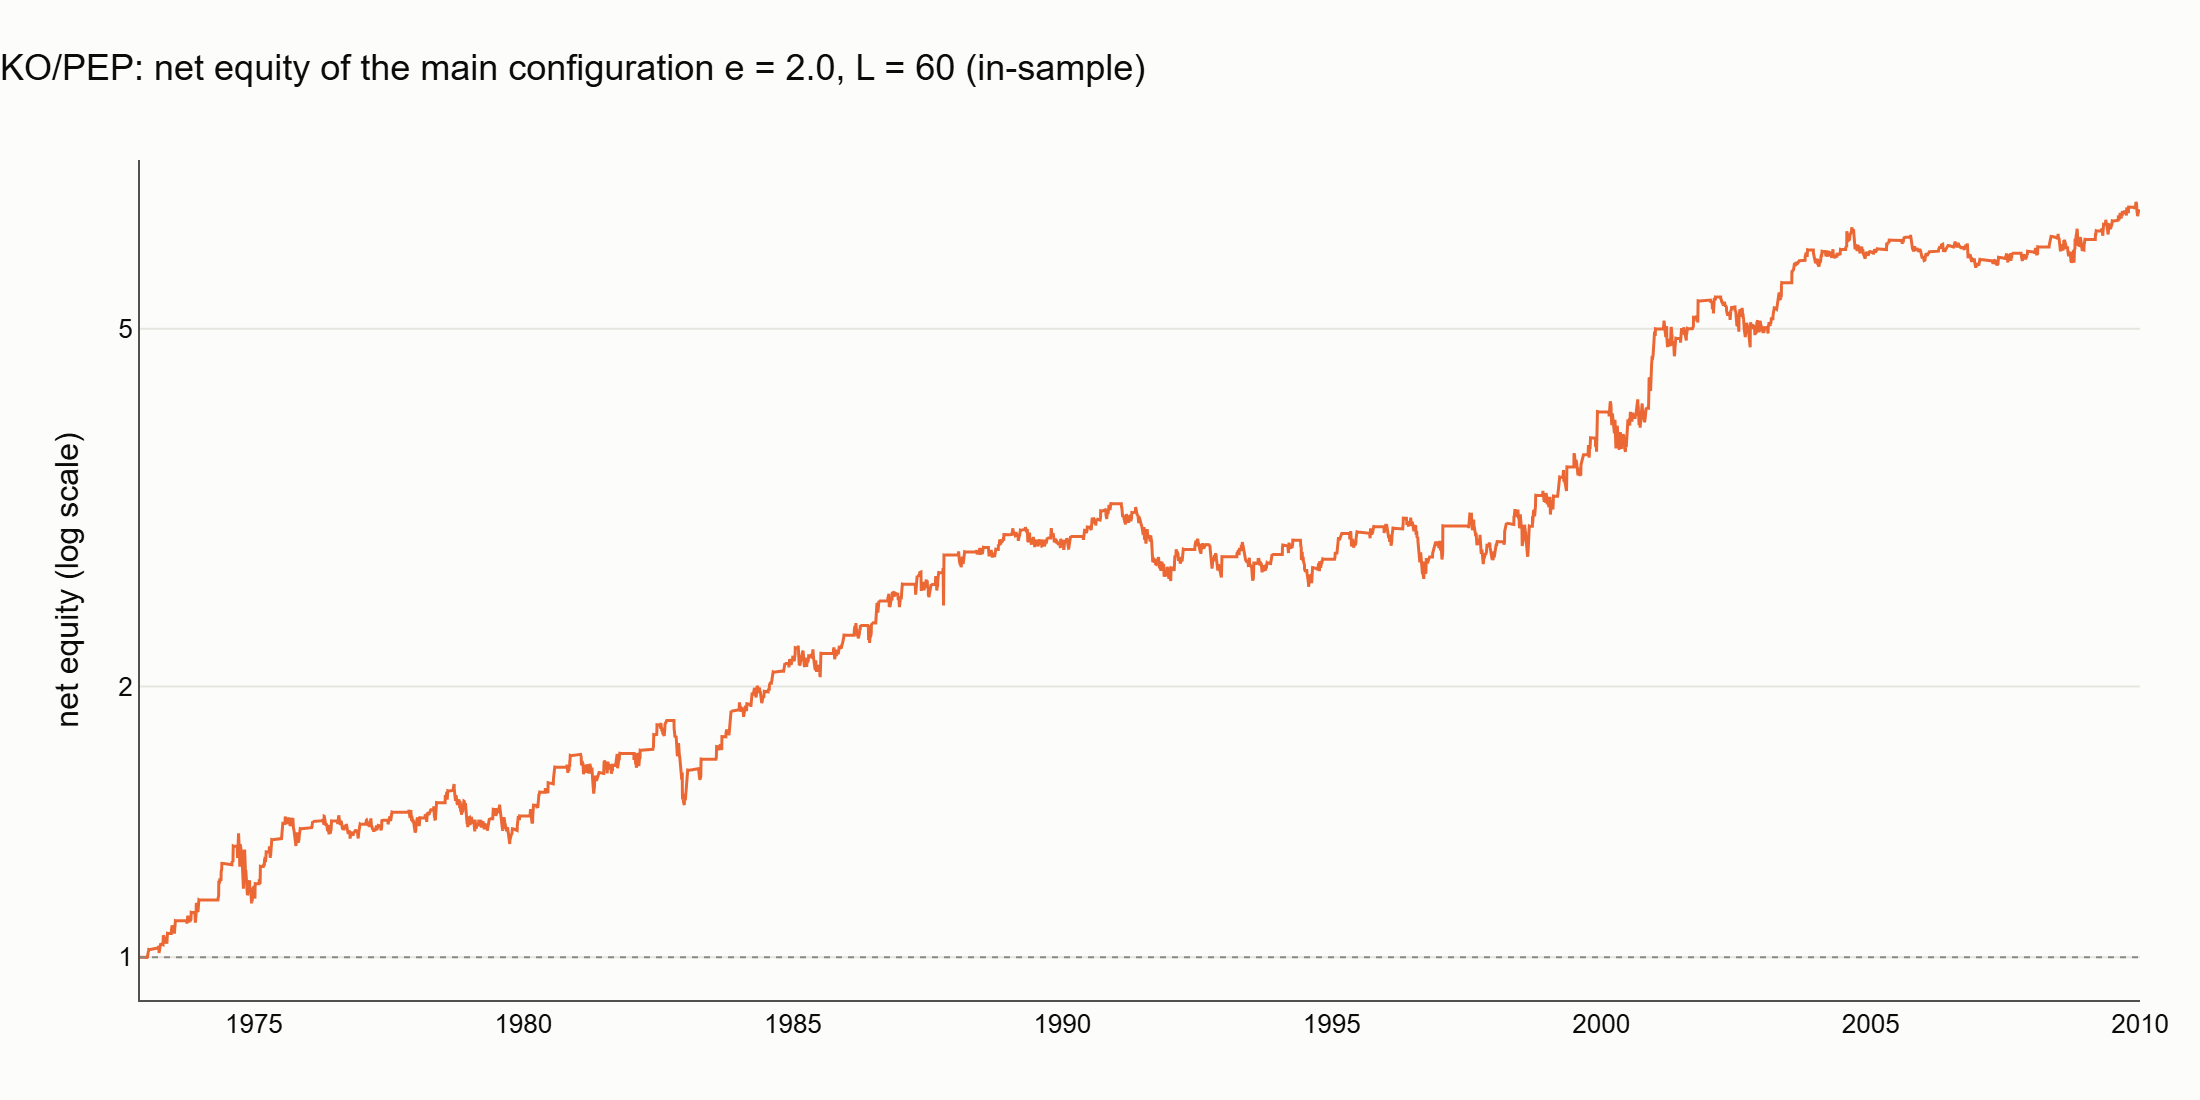

In [7]:
main_is = runs[(MAIN_ENTRY, MAIN_LOOKBACK)]
eq = (1 + main_is.daily["net_ret"]).cumprod()
fig = go.Figure()
fig.add_trace(go.Scatter(x=eq.index, y=eq, name="net", line={"color": "#eb6834", "width": 1.5}))
fig.add_hline(y=1, line={"color": "#8a8984", "width": 1, "dash": "dot"})
apply_style(fig, "KO/PEP: net equity of the main configuration e = 2.0, L = 60 (in-sample)")
fig.update_layout(showlegend=False)
fig.update_yaxes(
    type="log", tickvals=[0.1, 0.2, 0.5, 1, 2, 5, 10, 20], title_text="net equity (log scale)"
)
_, png = save_figure(fig, "appx_d_kopep_equity_is")
display(Image(filename=png))

In [8]:
table = grid.copy()
pct_cols = [c for c in table.columns if c.startswith(("ann_return", "ann_vol", "max_dd"))] + [
    "win_rate_net",
    "exposure",
]
table[pct_cols] = table[pct_cols] * 100
table = table.rename(columns={c: f"{c} %" for c in pct_cols}).astype(
    {"n_trades": int, "n_open_at_end": int}
)
table.round(2)

,entry_e,lookback_L,ann_return_gross %,ann_vol_gross %,sharpe_gross,max_dd_gross %,ann_return_net %,ann_vol_net %,sharpe_net,max_dd_net %,n_trades,win_rate_net %,avg_duration_days,max_duration_days,exposure %,n_open_at_end
0,1.5,20,10.32,10.68,0.97,-22.93,8.76,10.69,0.84,-23.09,530,75.85,11.20,76.0,63.39,1
1,1.5,60,7.03,10.68,0.69,-20.40,6.37,10.68,0.63,-20.48,229,79.48,26.20,173.0,64.06,1
2,1.5,120,5.11,10.57,0.52,-21.37,4.72,10.57,0.49,-21.45,136,77.21,44.82,201.0,65.09,1
3,2.0,20,9.21,9.24,1.00,-20.41,8.18,9.24,0.90,-20.57,351,77.49,12.04,72.0,45.13,1
4,2.0,60,5.75,9.82,0.62,-19.42,5.28,9.82,0.57,-19.50,166,77.71,30.00,172.0,53.17,1
5,2.0,120,4.10,9.89,0.46,-21.37,3.81,9.89,0.43,-21.45,102,77.45,51.34,201.0,55.92,1
6,2.5,20,4.82,6.40,0.77,-19.42,4.40,6.39,0.71,-19.50,151,76.16,12.91,60.0,20.81,1
7,2.5,60,4.04,7.98,0.54,-23.90,3.76,7.98,0.50,-24.81,101,77.23,32.09,172.0,34.60,1
8,2.5,120,2.62,8.54,0.35,-25.89,2.45,8.54,0.33,-26.70,63,77.78,60.06,200.0,40.40,1


## 4. Appendix OOS access #1 — single out-of-sample run of the main configuration

Logged in `EXPERIMENTS.md` (2026-10-10 17:10 CEST) before computing. β = 0.9805 frozen from the IS; e = 2.0, L = 60; z-score warm-up from the last IS days; starts flat on the first OOS trading day (2010-01-04).

In [9]:
OOS_END = date(2026, 10, 10)  # exclusive: last available date is 2026-10-09
prices = load_pair(end=OOS_END, ticker_a=A, ticker_b=B)
assert prices.index.max() == pd.Timestamp("2026-10-09")
assert round(fit.beta, 4) == 0.9805 and fit.last_date < SPLIT  # frozen IS beta

oos_run = run_strategy(
    prices,
    fit.beta,
    entry=MAIN_ENTRY,
    lookback=MAIN_LOOKBACK,
    end=OOS_END,
    trade_from=SPLIT,
    cost_bps=COST_BPS,
    ticker_a=A,
    ticker_b=B,
)
assert oos_run.daily["position"].iloc[0] == 0 and oos_run.daily.index[0] >= pd.Timestamp(SPLIT)

compare = pd.DataFrame(
    {
        "IS (1972-11-20 → 2009-12-31)": performance_summary(main_is.daily, main_is.trades),
        "OOS (2010-01-04 → 2026-10-09)": performance_summary(oos_run.daily, oos_run.trades),
    }
)
pct_prefixes = ("ann_return", "ann_vol", "max_dd")
pct_rows = [r for r in compare.index if r.startswith(pct_prefixes)] + ["win_rate_net", "exposure"]
compare.loc[pct_rows] = compare.loc[pct_rows] * 100
compare = compare.rename(index={r: f"{r} %" for r in pct_rows})
compare.round(2)

WARNING pairs.data: Alignment dropped 2599 rows present in only one series


INFO pairs.data: Loaded KO/PEP: 13703 common days, 1972-06-01 -> 2026-10-09 (end=2026-10-10, exclusive)


INFO pairs.backtest: log e=2.0 L=60 lag=1: 62 trades, 2010-01-04..2026-10-09


,IS (1972-11-20 → 2009-12-31),OOS (2010-01-04 → 2026-10-09)
ann_return_gross %,5.75,-0.99
ann_vol_gross %,9.82,5.61
sharpe_gross,0.62,-0.15
max_dd_gross %,-19.42,-27.16
ann_return_net %,5.28,-1.35
ann_vol_net %,9.82,5.60
sharpe_net,0.57,-0.21
max_dd_net %,-19.50,-28.39
n_trades,166.00,62.00
win_rate_net %,77.71,62.90


INFO pairs.plotting: Saved figure appx_e_kopep_equity_oos (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


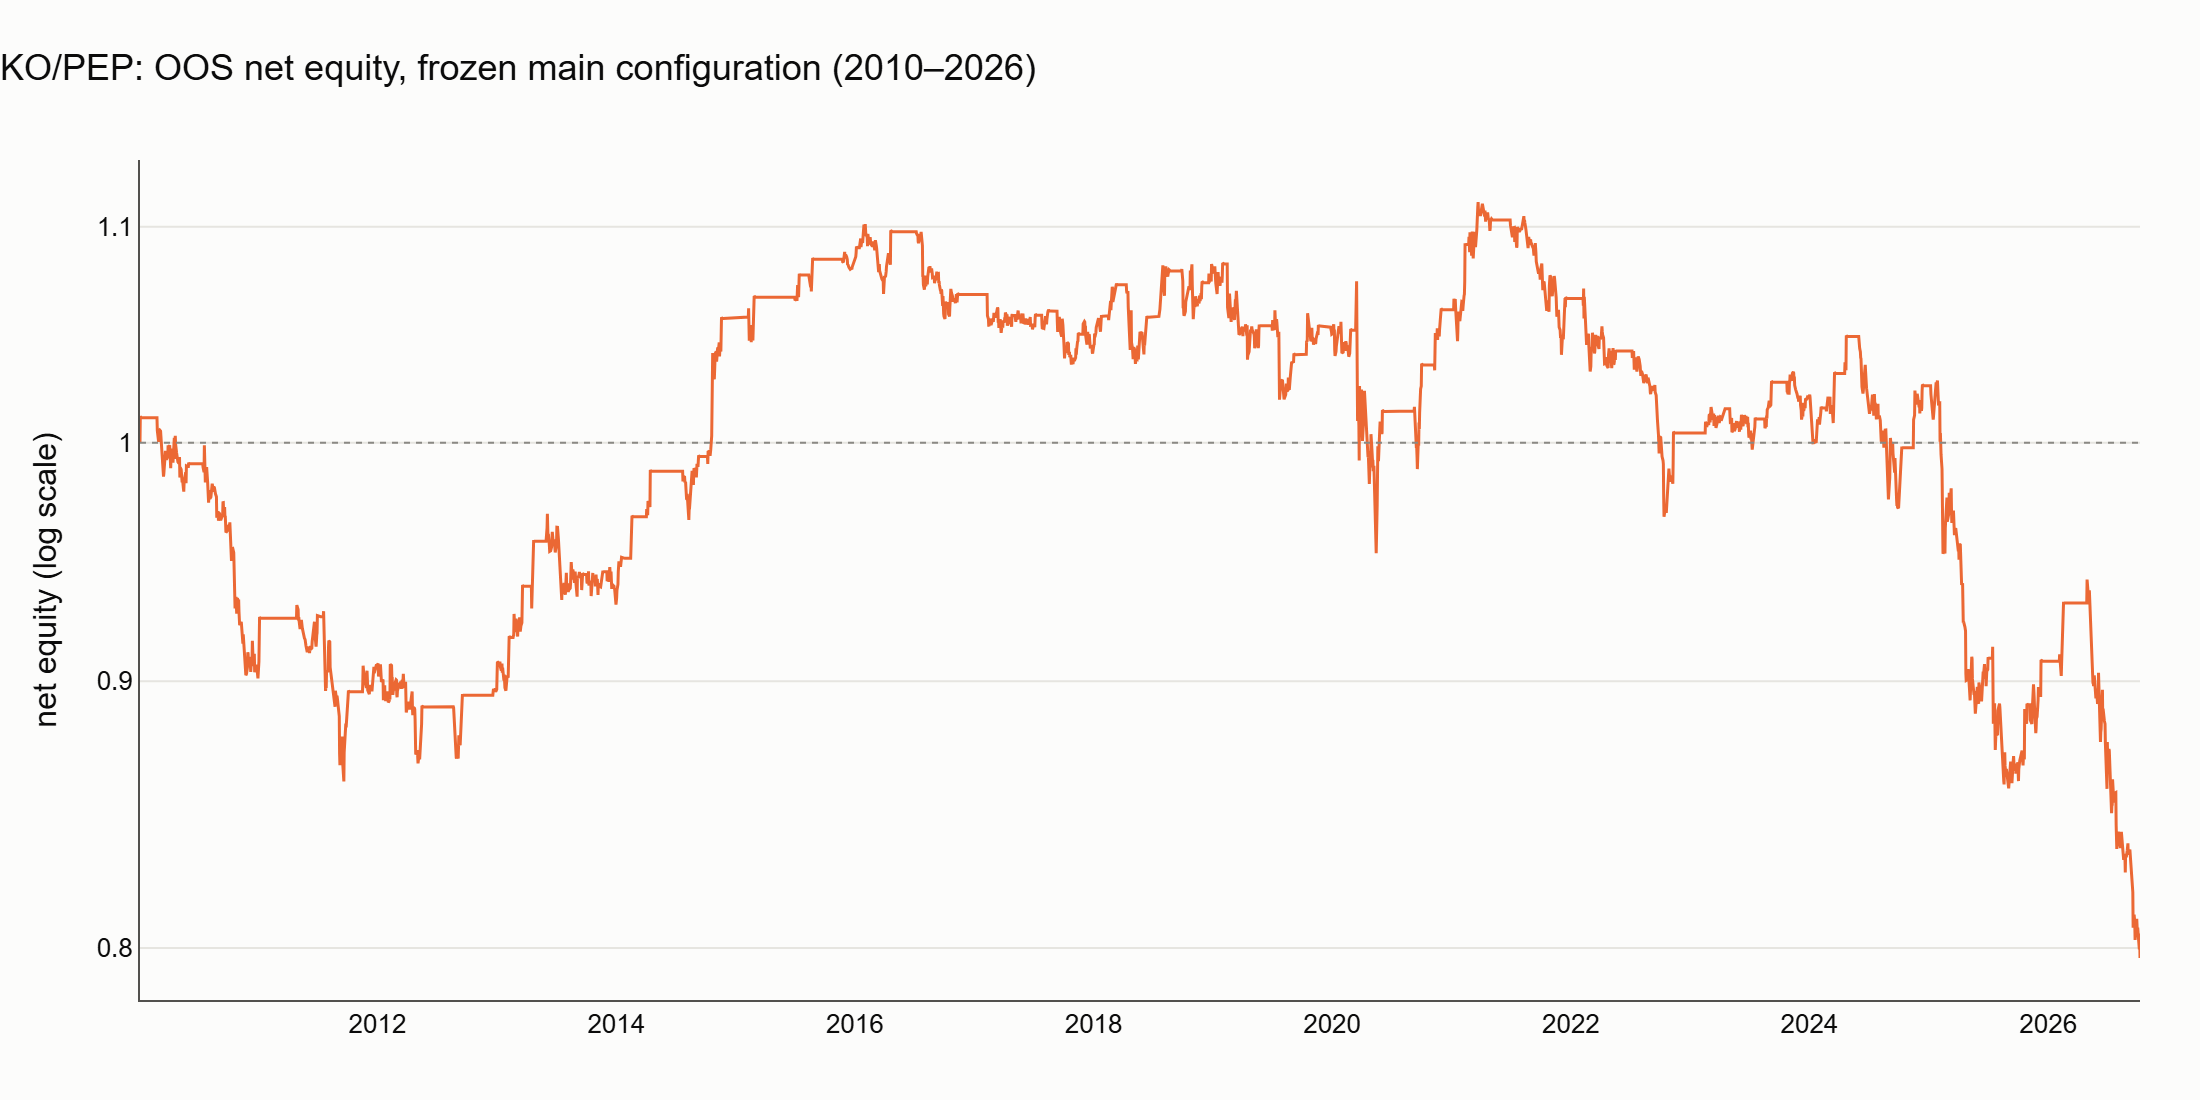

,statistic,p_value
"ADF on OOS spread, frozen β (lags=9)",-0.1239,0.9470
Engle–Granger on OOS log prices (own β),0.5331,0.9929


In [10]:
eq_oos = (1 + oos_run.daily["net_ret"]).cumprod()
fig = go.Figure()
fig.add_trace(
    go.Scatter(x=eq_oos.index, y=eq_oos, name="net", line={"color": "#eb6834", "width": 1.5})
)
fig.add_hline(y=1, line={"color": "#8a8984", "width": 1, "dash": "dot"})
apply_style(fig, "KO/PEP: OOS net equity, frozen main configuration (2010–2026)")
fig.update_layout(showlegend=False)
fig.update_yaxes(
    type="log",
    tickvals=[0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.2, 1.3, 1.5],
    title_text="net equity (log scale)",
)
_, png = save_figure(fig, "appx_e_kopep_equity_oos")
display(Image(filename=png))

prices_oos = prices[prices.index >= pd.Timestamp(SPLIT)]
st_oos = stationarity_tests(prices_oos, beta=fit.beta, end=OOS_END, ticker_a=A, ticker_b=B)
pd.DataFrame(
    {
        "statistic": [st_oos.adf_stat, st_oos.eg_stat],
        "p_value": [st_oos.adf_pvalue, st_oos.eg_pvalue],
    },
    index=[
        f"ADF on OOS spread, frozen β (lags={st_oos.adf_lags})",
        "Engle–Granger on OOS log prices (own β)",
    ],
).round(4)

## 5. Full history (1972–2026), generated after the OOS run

Descriptive only; the IS-only chart above is unchanged. Dashed vertical line: the IS/OOS split (2010-01-01).

INFO pairs.plotting: Saved figure appx_f_kopep_prices_ratio_full (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


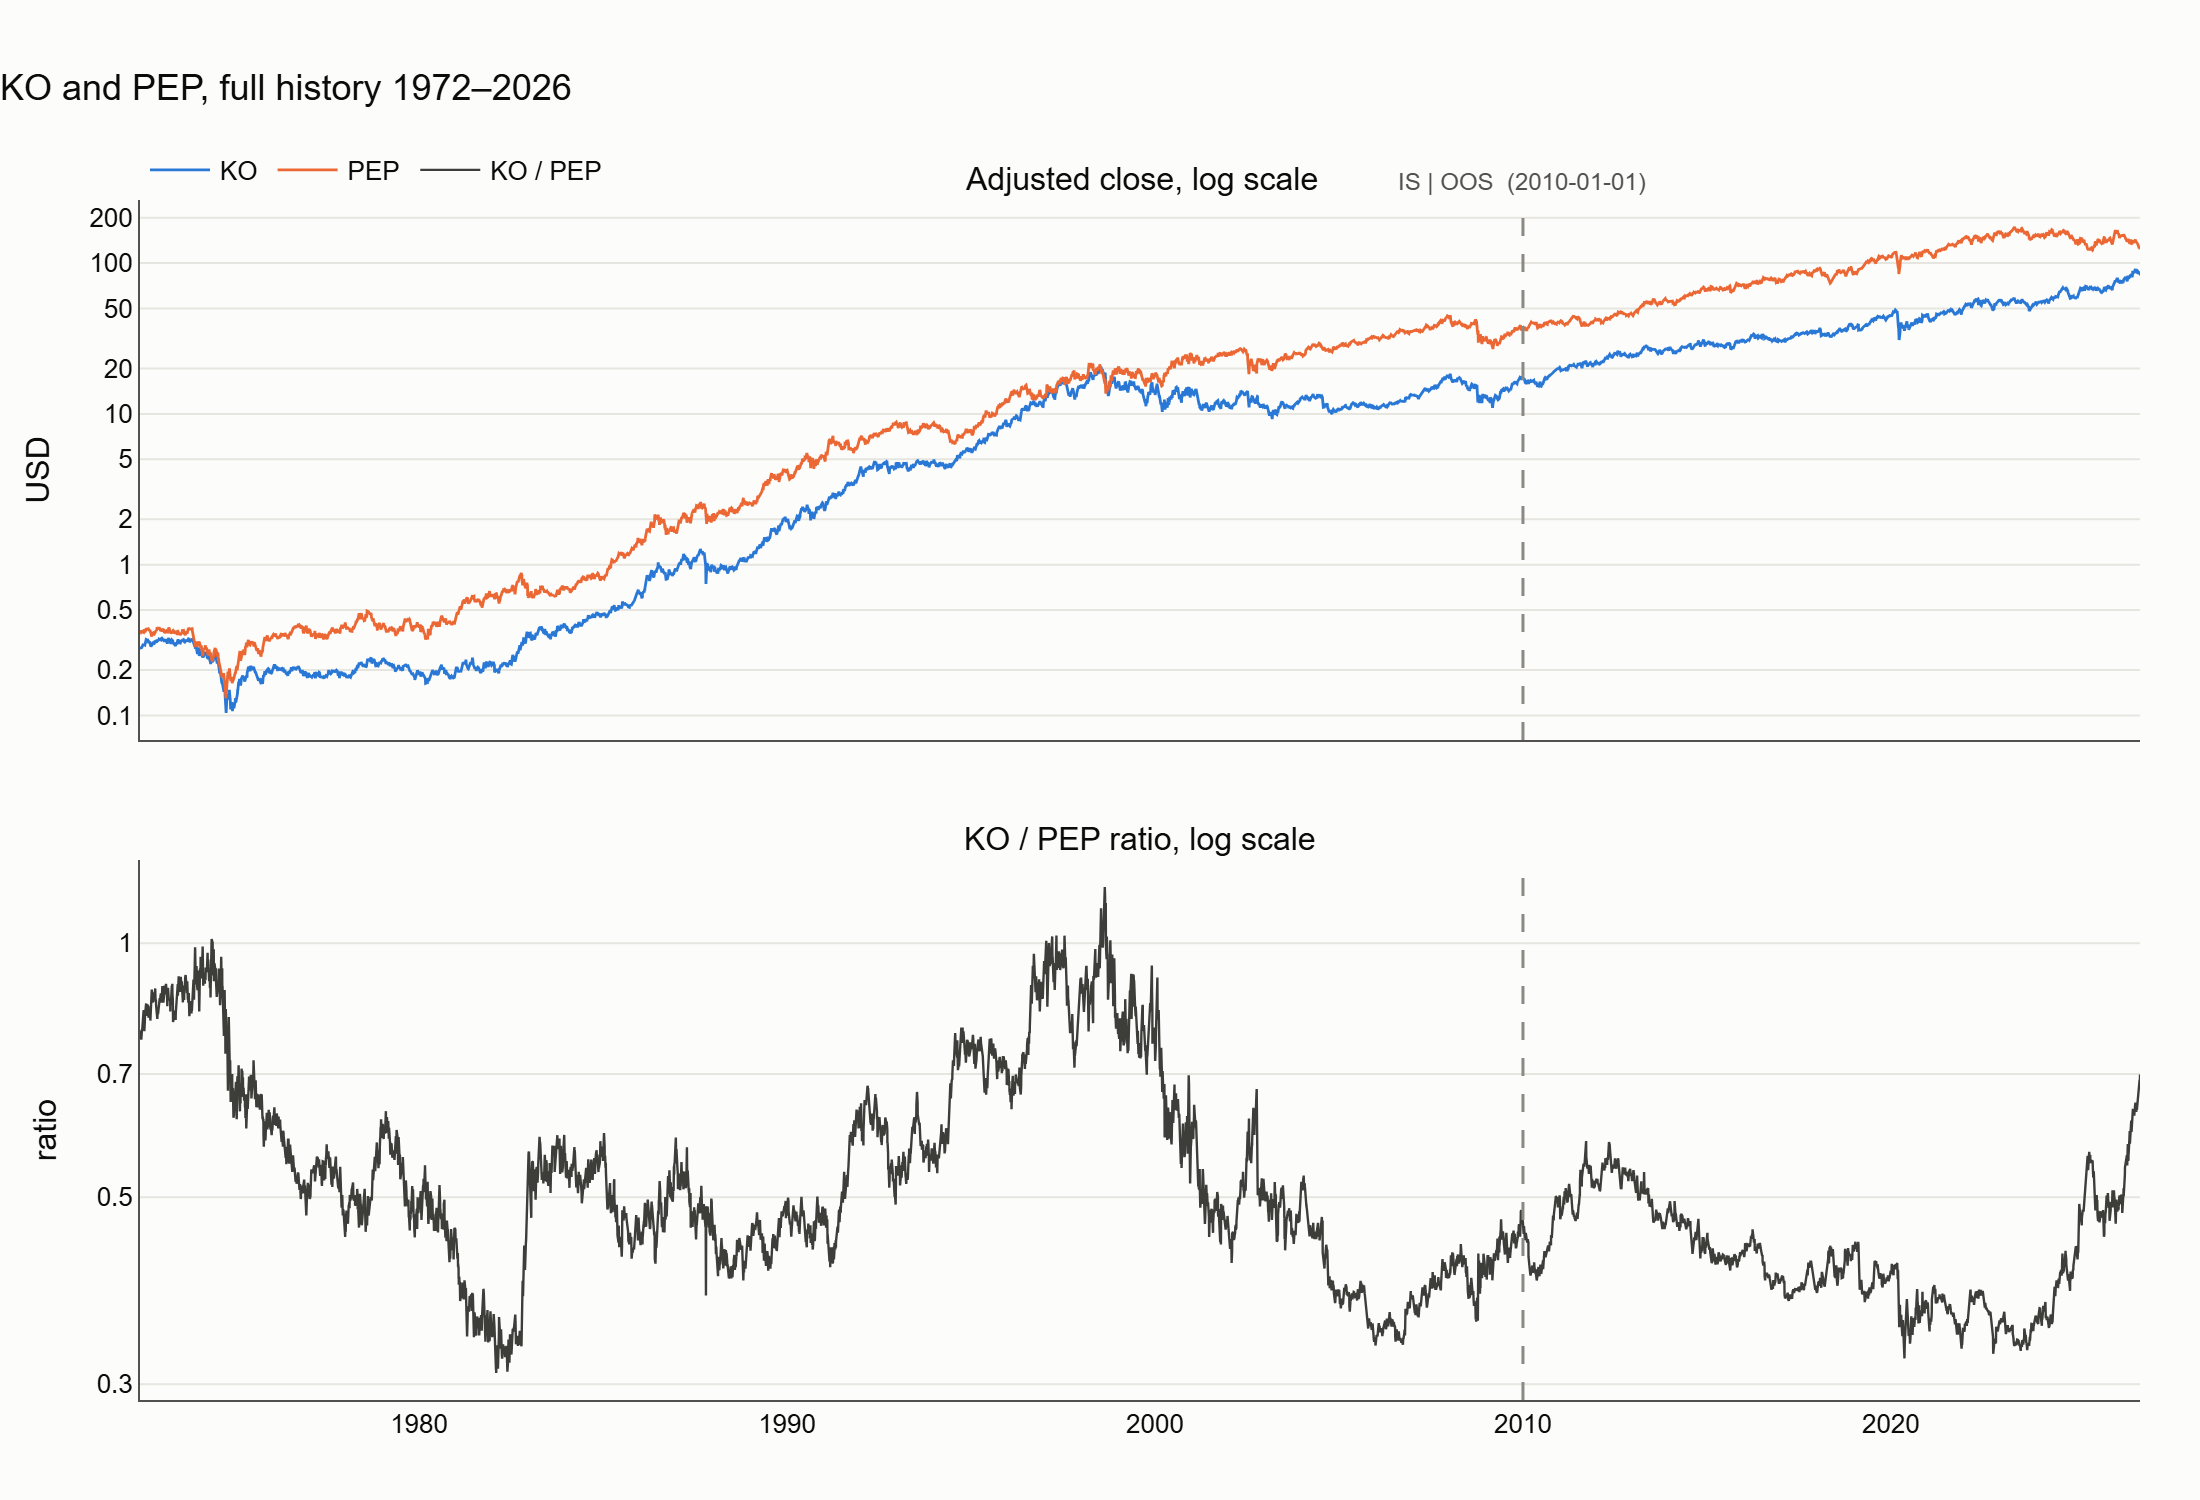

In [11]:
fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.10,
    subplot_titles=("Adjusted close, log scale", "KO / PEP ratio, log scale"),
)
for t in (A, B):
    fig.add_trace(
        go.Scatter(x=prices.index, y=prices[t], name=t, line={"color": COLORS[t], "width": 1.4}),
        row=1,
        col=1,
    )
ratio = prices[A] / prices[B]
fig.add_trace(
    go.Scatter(
        x=ratio.index, y=ratio, name="KO / PEP", line={"color": DERIVED_COLOR, "width": 1.2}
    ),
    row=2,
    col=1,
)
split_ts = pd.Timestamp(SPLIT)
fig.add_vline(
    x=split_ts, line={"color": "#8a8984", "width": 1.5, "dash": "dash"}, row="all", col="all"
)
fig.add_annotation(
    x=split_ts,
    y=1.0,
    xref="x",
    yref="paper",
    text="IS | OOS  (2010-01-01)",
    showarrow=False,
    xanchor="center",
    yanchor="bottom",
    font={"size": 12, "color": "#52514e"},
)
apply_style(fig, "KO and PEP, full history 1972–2026")
fig.update_layout(margin={"t": 100})
fig.update_yaxes(
    type="log",
    tickvals=[0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200],
    title_text="USD",
    row=1,
    col=1,
)
fig.update_yaxes(
    type="log",
    tickvals=[0.1, 0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 5],
    title_text="ratio",
    row=2,
    col=1,
)
_, png = save_figure(fig, "appx_f_kopep_prices_ratio_full", height=750)
display(Image(filename=png))

## Observations

- **Cointegration in the IS (1972–2009): not significant at 5%.** β = 0.98 and R² = 0.975, but Engle–Granger p = 0.45 (ADF p = 0.22); half-life ≈ 386 trading days (≈ 1.5 years). Much closer to a relationship than INTC/AMD (EG p 0.975, half-life ≈ 27 years), yet the long-run spread still wanders in multi-year swings.
- **IS: the strategy earns, robustly across the grid.** Main configuration: net Sharpe 0.57, +5.3% a year, max drawdown −19.5%, 166 trades, win rate 78%. All nine configurations are positive (net Sharpe 0.33–0.90); shorter lookbacks do better. The rolling z-score captures short-term reversion around the slow swings.
- **OOS (single run, β frozen): the result does not hold.** Net Sharpe −0.21, −1.35% a year, max drawdown −28%. The equity is roughly flat-to-positive until 2021, then gives everything back, with the largest loss in 2025–2026, when the KO/PEP ratio rose sharply (KO strongly outperforming PEP) and the strategy, short the spread, kept losing as it kept rising. Descriptive OOS tests: ADF p = 0.95 (frozen β), Engle–Granger p = 0.99 (own β): no stable relationship in 2010–2026.
- **What the appendix says about the pipeline and about INTC/AMD.** The pipeline does find in-sample profits when the spread reverts on short horizons (and the synthetic positive control showed it finds genuine cointegration), so the INTC/AMD failure is not a pipeline artefact. But even the textbook pair, robust across the whole IS grid, fails its single honest OOS test: a good in-sample grid is not evidence of a durable relationship. This is one more pair and one more OOS test; it does not change any INTC/AMD conclusion.

## 6. Diagnostic — Phase 3 on KO/PEP: rolling β and rolling ADF (full history)

Pre-registered in `EXPERIMENTS.md` (2026-10-10 17:24 CEST) **after** seeing the KO/PEP IS and OOS results, to explain the out-of-sample decay. No new strategy backtest and no new OOS access. Identical methods and parameters to INTC/AMD: W = 252 days, ADF every 21 days on the window's own-β spread, weak = p > 0.05, flag of day t from data up to t − 1. Weak vs strong comparison of the main configuration's **already computed** daily net returns, separately for IS and OOS.

In [12]:
from pairs.config import PROCESSED_DIR
from pairs.plotting import shade_periods
from pairs.simulation import BootstrapParams, load_or_simulate
from pairs.stability import regime_comparison, rolling_adf, rolling_beta, weak_flag

beta_roll = rolling_beta(prices, end=OOS_END, ticker_a=A, ticker_b=B)
adf = rolling_adf(prices, end=OOS_END, ticker_a=A, ticker_b=B)
flag = weak_flag(adf, pd.DatetimeIndex(prices.index))
split_ts = pd.Timestamp(SPLIT)

b = beta_roll.dropna()
f = flag.dropna().astype(bool)
stats3 = pd.DataFrame(
    {
        period: {
            "rolling β median": s_b.median(),
            "rolling β 5th pct": s_b.quantile(0.05),
            "rolling β 95th pct": s_b.quantile(0.95),
            "% days β ≤ 0.1": 100 * (s_b <= 0.1).mean(),
            "% flagged days weak (ADF p > 0.05)": 100 * s_f.mean(),
            "flagged days": len(s_f),
        }
        for period, s_b, s_f in (
            ("IS (to 2009-12-31)", b[b.index < split_ts], f[f.index < split_ts]),
            ("OOS (from 2010-01-01)", b[b.index >= split_ts], f[f.index >= split_ts]),
        )
    }
)
print(
    f"{len(adf)} rolling ADF windows, {adf.index[0].date()} -> {adf.index[-1].date()}; "
    f"static IS β = {fit.beta:.3f}"
)
stats3.round(3)

INFO pairs.stability: Rolling ADF: 641 windows of 252 days every 21 days, 1973-06-04..2026-09-24


641 rolling ADF windows, 1973-06-04 -> 2026-09-24; static IS β = 0.981


,IS (to 2009-12-31),OOS (from 2010-01-01)
rolling β median,0.703,0.651
rolling β 5th pct,0.003,-0.117
rolling β 95th pct,1.318,1.357
% days β ≤ 0.1,8.609,9.720
% flagged days weak (ADF p > 0.05),68.840,80.085
flagged days,9233.000,4218.000


In [13]:
by_decade = (
    pd.DataFrame({"weak": f, "decade": (f.index.year // 10) * 10})
    .groupby("decade")["weak"]
    .agg(flagged_days="size", weak_pct=lambda w: 100 * w.mean())
)
by_decade.index = [f"{d}s" for d in by_decade.index]
by_decade.round(1)

,flagged_days,weak_pct
1970s,1662,62.1
1980s,2528,61.8
1990s,2528,67.6
2000s,2515,81.6
2010s,2516,72.5
2020s,1702,91.4


INFO pairs.plotting: Saved figure appx_g_kopep_rolling_beta (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


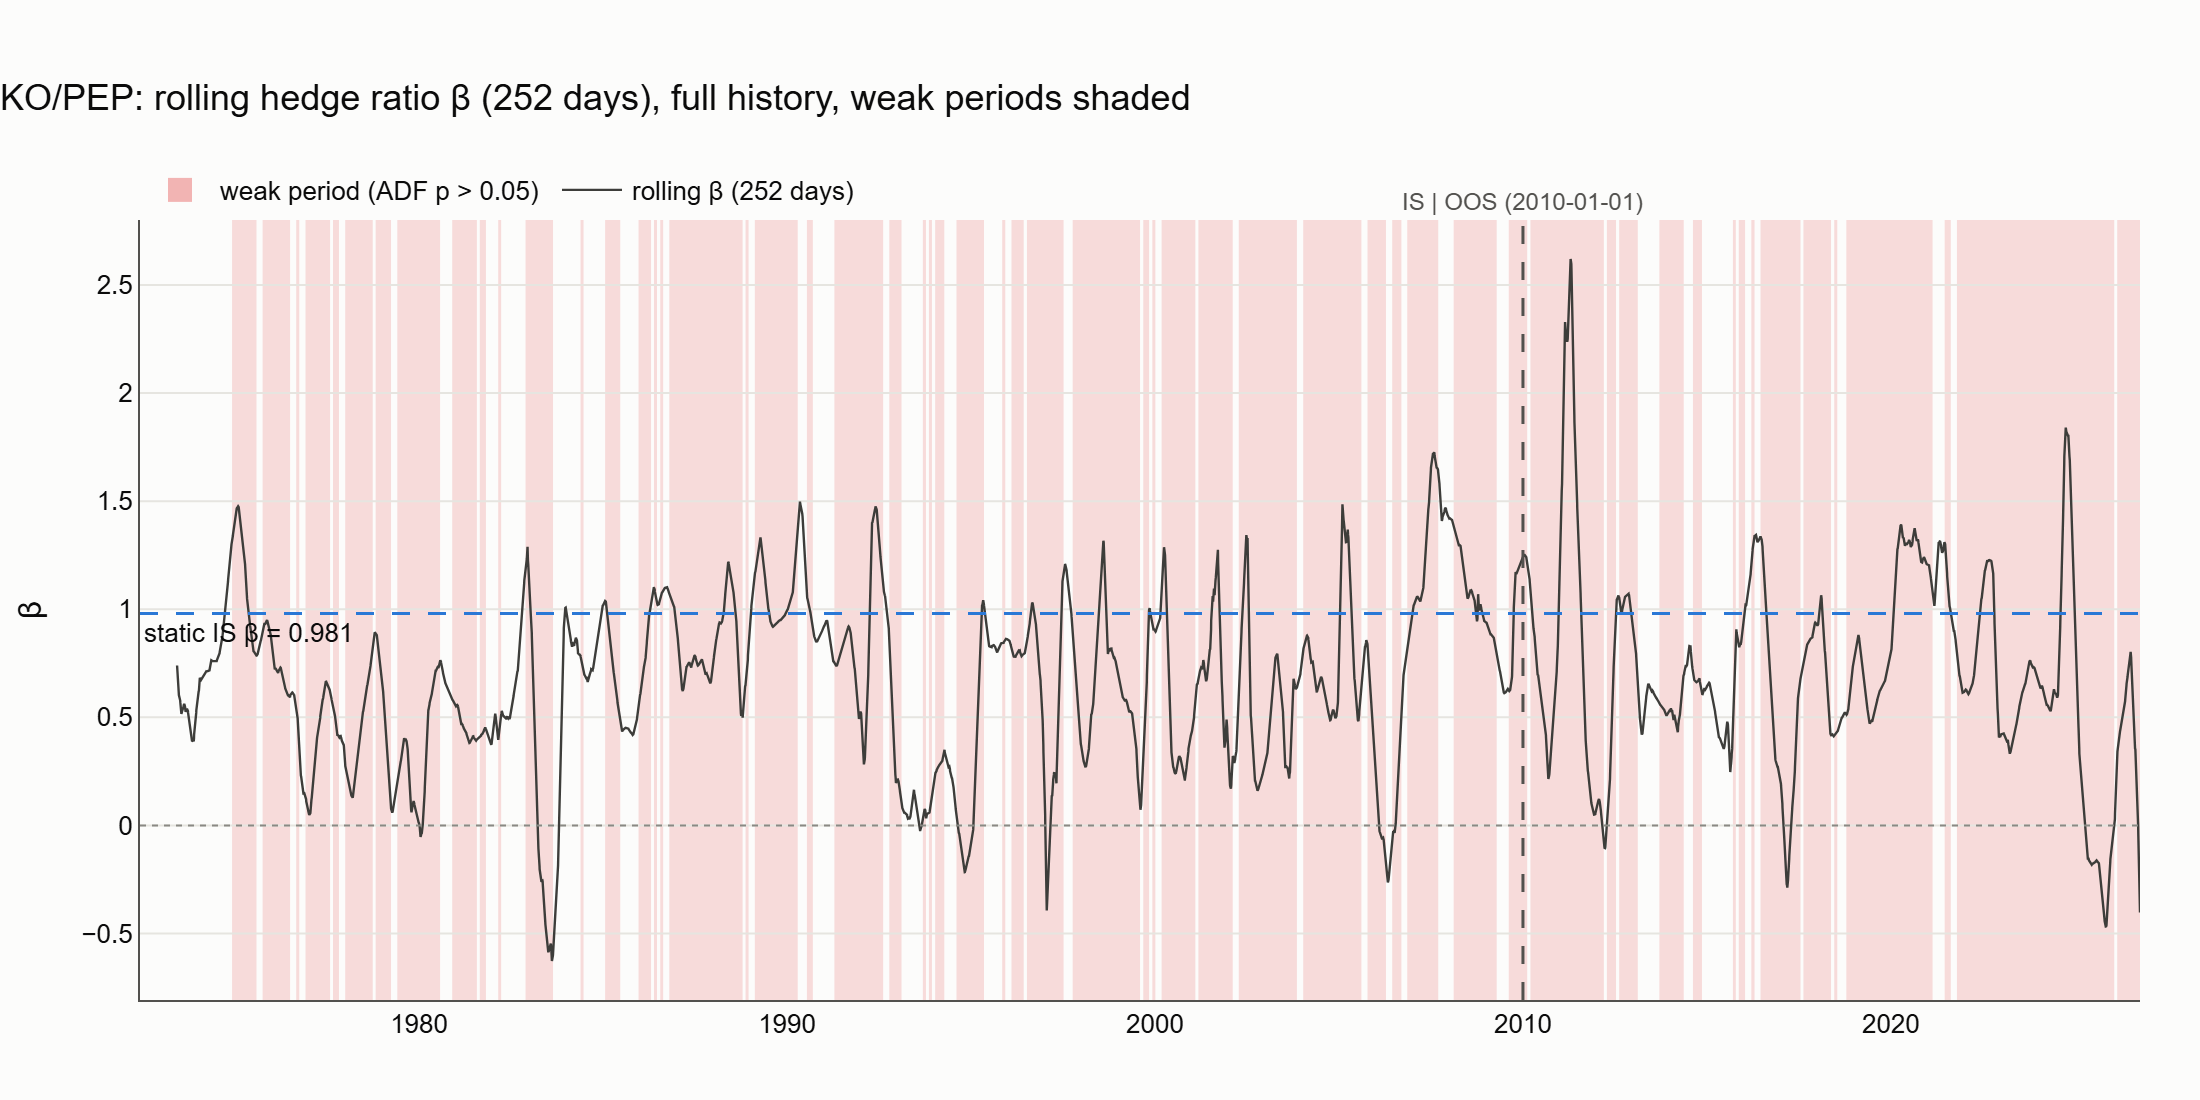

INFO pairs.plotting: Saved figure appx_h_kopep_rolling_adf (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


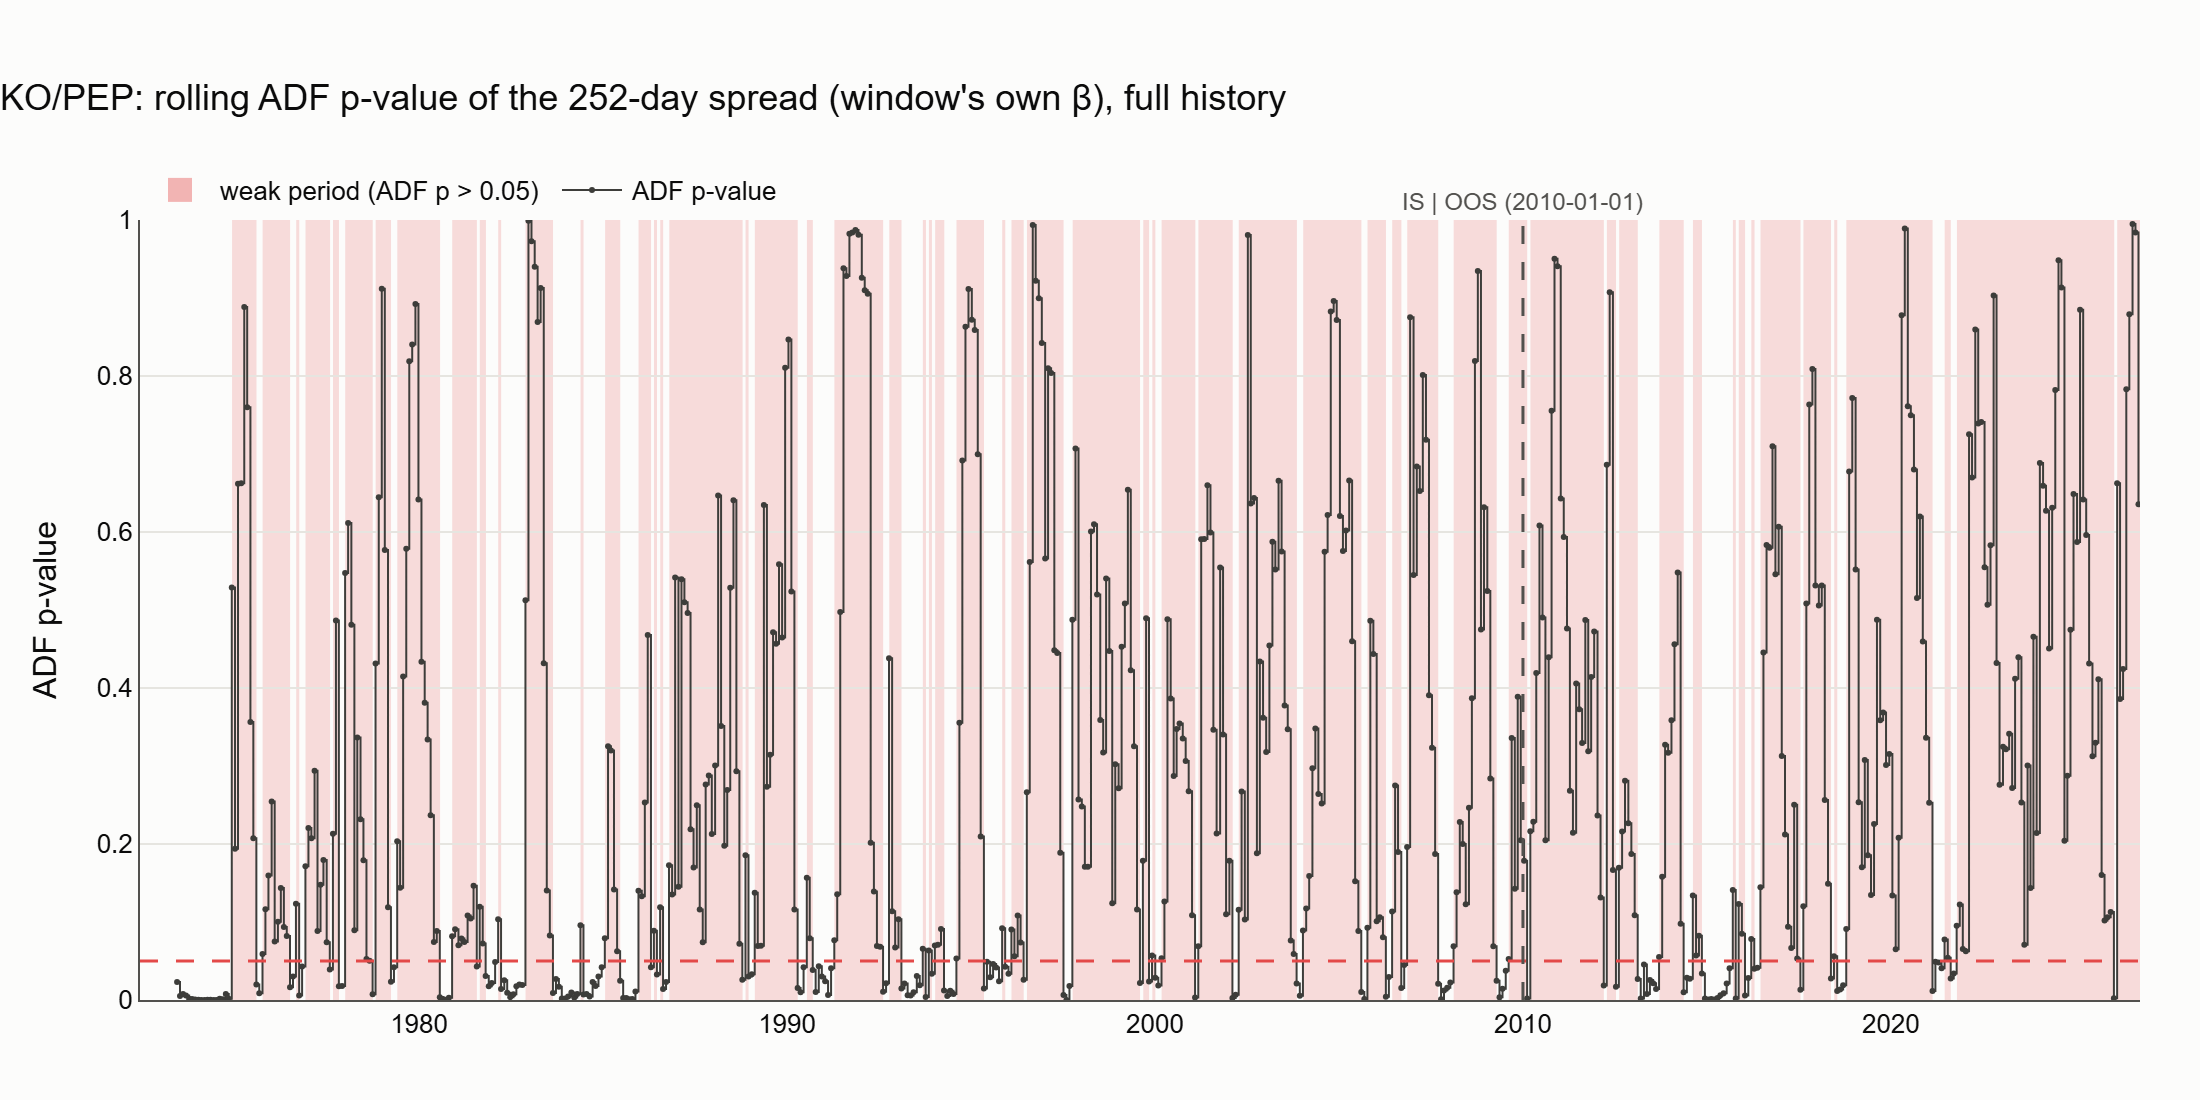

In [14]:
def mark_split(fig: go.Figure) -> None:
    fig.add_vline(x=split_ts, line={"color": "#52514e", "width": 1.5, "dash": "dash"})
    fig.add_annotation(
        x=split_ts,
        y=1.0,
        yref="paper",
        text="IS | OOS (2010-01-01)",
        showarrow=False,
        xanchor="center",
        yanchor="bottom",
        font={"size": 12, "color": "#52514e"},
    )


fig = go.Figure()
shade_periods(fig, flag, label="weak period (ADF p > 0.05)")
fig.add_trace(
    go.Scatter(
        x=beta_roll.index,
        y=beta_roll,
        name="rolling β (252 days)",
        line={"color": DERIVED_COLOR, "width": 1.2},
    )
)
fig.add_hline(
    y=fit.beta,
    line={"color": "#2a78d6", "width": 1.5, "dash": "dash"},
    annotation_text=f"static IS β = {fit.beta:.3f}",
    annotation_position="bottom left",
)
fig.add_hline(y=0, line={"color": "#8a8984", "width": 1, "dash": "dot"})
mark_split(fig)
apply_style(fig, "KO/PEP: rolling hedge ratio β (252 days), full history, weak periods shaded")
fig.update_layout(margin={"t": 110})
fig.update_xaxes(range=[prices.index[0], prices.index[-1]])
fig.update_yaxes(title_text="β")
_, png = save_figure(fig, "appx_g_kopep_rolling_beta")
display(Image(filename=png))

fig = go.Figure()
shade_periods(fig, flag, label="weak period (ADF p > 0.05)")
fig.add_trace(
    go.Scatter(
        x=adf.index,
        y=adf["adf_pvalue"],
        name="ADF p-value",
        mode="lines+markers",
        line={"color": DERIVED_COLOR, "width": 1, "shape": "hv"},
        marker={"size": 3},
    )
)
fig.add_hline(y=0.05, line={"color": "#e34948", "width": 1.5, "dash": "dash"})
mark_split(fig)
apply_style(fig, "KO/PEP: rolling ADF p-value of the 252-day spread (window's own β), full history")
fig.update_layout(margin={"t": 110})
fig.update_xaxes(range=[prices.index[0], prices.index[-1]])
fig.update_yaxes(title_text="ADF p-value", range=[0, 1])
_, png = save_figure(fig, "appx_h_kopep_rolling_adf")
display(Image(filename=png))

### Does the main configuration earn less on weak days? IS and OOS separately (already computed daily net returns)

In [15]:
def regime_table(daily: pd.DataFrame, trades: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    cmp = regime_comparison(daily, trades, flag)
    t = cmp.table.copy()
    for col in ["share_days", "exposure", "ann_return", "max_dd", "win_rate_net"]:
        t[col] = 100 * t[col]
    t["mean_daily_net"] = 1e4 * t["mean_daily_net"]
    t = t.rename(
        columns={
            "share_days": "share_days %",
            "exposure": "exposure %",
            "mean_daily_net": "mean_daily_net bp",
            "ann_return": "ann_return %",
            "max_dd": "max_dd (stitched) %",
            "win_rate_net": "win_rate_net %",
        }
    ).astype({"n_days": int, "n_trades": int})
    note = (
        f"Welch t = {cmp.welch_t:.2f}, p = {cmp.welch_pvalue:.3f} (approximate); "
        f"excluded without a flag: {cmp.n_days_unflagged} days, {cmp.n_trades_unflagged} trades."
    )
    return t.round(2), note


for name, run in (("IS", main_is), ("OOS", oos_run)):
    t, note = regime_table(run.daily, run.trades)
    print(f"--- {name} ---  {note}")
    display(t)

--- IS ---  Welch t = 1.25, p = 0.210 (approximate); excluded without a flag: 133 days, 3 trades.


,n_days,share_days %,exposure %,mean_daily_net bp,ann_return %,sharpe,max_dd (stitched) %,n_trades,win_rate_net %
weak,6356,68.84,55.62,2.72,6.54,0.67,-17.26,105,80.95
strong,2877,31.16,48.56,1.05,2.26,0.29,-23.95,58,70.69


--- OOS ---  Welch t = -1.28, p = 0.199 (approximate); excluded without a flag: 0 days, 0 trades.


,n_days,share_days %,exposure %,mean_daily_net bp,ann_return %,sharpe,max_dd (stitched) %,n_trades,win_rate_net %
weak,3378,80.09,63.56,-0.77,-2.09,-0.33,-29.78,48,58.33
strong,840,19.91,46.90,0.69,1.66,0.40,-4.71,14,78.57


## 7. Diagnostic — Phase 5 on KO/PEP: joint block bootstrap

Pre-registered at 17:24 CEST (after seeing the KO/PEP results). Identical to INTC/AMD: moving blocks of 20 days with the same dates for both stocks, 500 paths, seed 2026, split at the real KO/PEP split position (row 9,485); on each path β by OLS on the simulated IS, Engle–Granger on the simulated IS, main configuration on simulated IS and OOS (β frozen). The paths represent **two correlated stocks without a stable relationship** beyond 20 days. Computed once by `scripts/run_simulation.py`; reloaded here from `data/processed/simulation_paths_KO_PEP.pkl`.

In [16]:
params_kp = BootstrapParams(split_index=int((prices.index < split_ts).sum()))
assert params_kp.split_index == 9485 and params_kp.n_paths == 500 and params_kp.seed == 2026
sims = load_or_simulate(prices, params_kp, PROCESSED_DIR / "simulation_paths_KO_PEP.pkl", A, B)
assert len(sims) == params_kp.n_paths and not sims.isna().to_numpy().any()

real = {
    "is": performance_summary(main_is.daily, main_is.trades)["sharpe_net"],
    "oos": performance_summary(oos_run.daily, oos_run.trades)["sharpe_net"],
    "eg": st.eg_pvalue,
}
assert (
    round(real["is"], 2) == 0.57
    and round(real["oos"], 2) == -0.21
    and round(real["eg"], 3) == 0.447
)


def describe(sim: pd.Series, value: float) -> dict[str, float]:
    return {
        "sim median": sim.median(),
        "sim 5th pct": sim.quantile(0.05),
        "sim 95th pct": sim.quantile(0.95),
        "share of paths > 0 (%)": 100 * (sim > 0).mean(),
        "real value": value,
        "percentile of real (%)": 100 * (sim <= value).mean(),
    }


summary5 = pd.DataFrame(
    {
        "Sharpe net, simulated IS": describe(sims["is_sharpe_net"], real["is"]),
        "Sharpe net, simulated OOS": describe(sims["oos_sharpe_net"], real["oos"]),
        "Engle–Granger p, simulated IS": describe(sims["eg_pvalue"], real["eg"]),
    }
)
summary5.loc["share of paths with p < 0.05 (%)"] = [
    np.nan,
    np.nan,
    100 * (sims["eg_pvalue"] < 0.05).mean(),
]
summary5.round(3)

INFO pairs.simulation: Loaded simulation table from C:\Users\cloti\Documents\Projects\challenge_BSQ\data\processed\simulation_paths_KO_PEP.pkl


,"Sharpe net, simulated IS","Sharpe net, simulated OOS","Engle–Granger p, simulated IS"
sim median,0.324,0.321,0.391
sim 5th pct,0.074,-0.083,0.047
sim 95th pct,0.578,0.665,0.922
share of paths > 0 (%),98.200,90.000,100.000
real value,0.573,-0.215,0.447
percentile of real (%),94.400,1.800,55.000
share of paths with p < 0.05 (%),NaN,NaN,5.400


INFO pairs.plotting: Saved figure appx_i_kopep_sharpe_bootstrap_vs_real (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


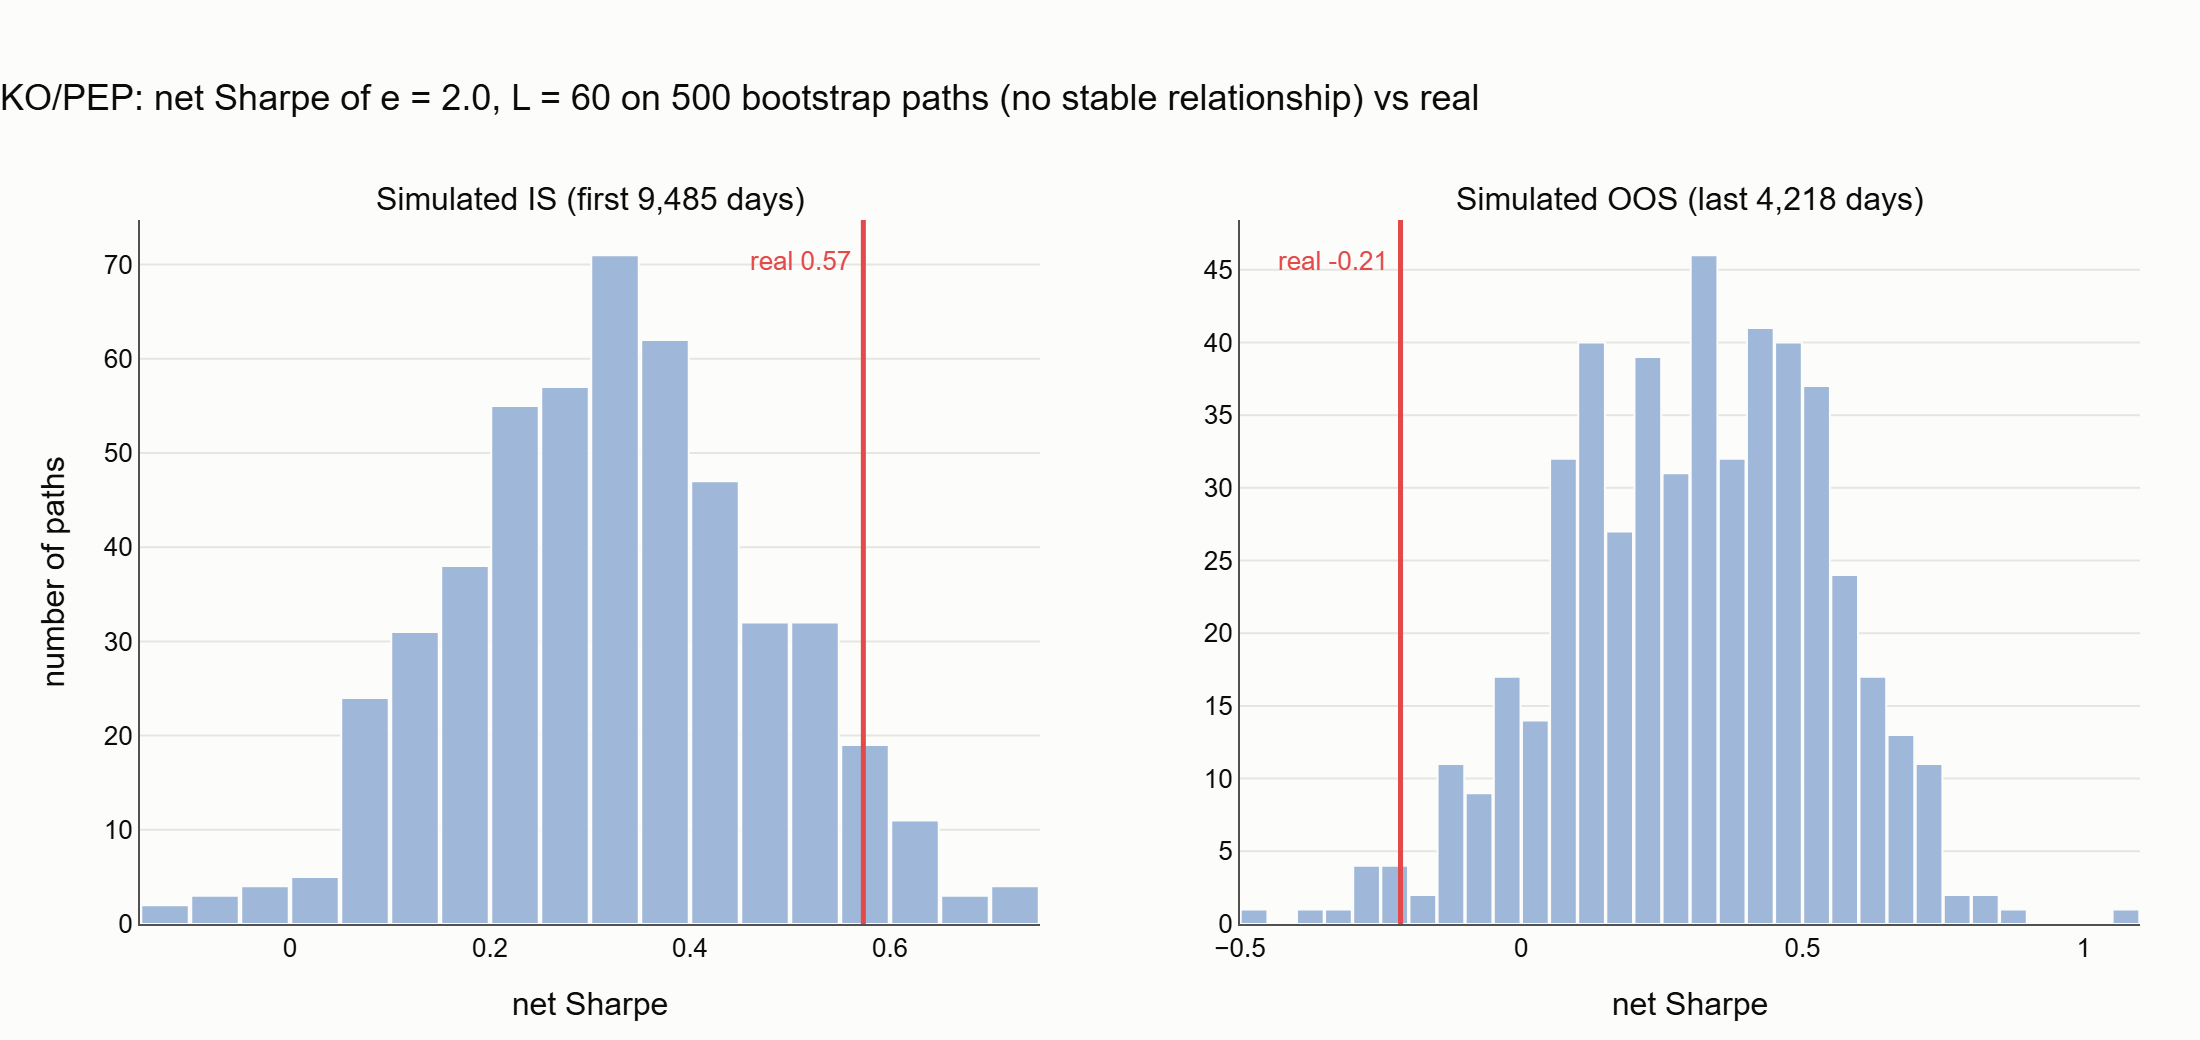

In [17]:
fig = make_subplots(
    rows=1,
    cols=2,
    horizontal_spacing=0.10,
    subplot_titles=("Simulated IS (first 9,485 days)", "Simulated OOS (last 4,218 days)"),
)
for col, key in enumerate(["is", "oos"], start=1):
    fig.add_trace(
        go.Histogram(
            x=sims[f"{key}_sharpe_net"],
            nbinsx=40,
            marker={"color": "#9fb8d9", "line": {"color": "#fcfcfb", "width": 1}},
        ),
        row=1,
        col=col,
    )
    fig.add_vline(x=real[key], line={"color": "#e34948", "width": 2.5}, row=1, col=col)
    fig.add_annotation(
        x=real[key],
        y=0.97,
        xref=f"x{'' if col == 1 else col}",
        yref=f"y{'' if col == 1 else col} domain",
        text=f"real {real[key]:.2f}",
        showarrow=False,
        xanchor="right",
        yanchor="top",
        xshift=-4,
        font={"color": "#e34948", "size": 13},
    )
    fig.update_xaxes(title_text="net Sharpe", row=1, col=col)
fig.update_yaxes(title_text="number of paths", row=1, col=1)
apply_style(
    fig,
    "KO/PEP: net Sharpe of e = 2.0, L = 60 on 500 bootstrap paths (no stable relationship) vs real",
)
fig.update_layout(bargap=0.05, hovermode="closest", margin={"t": 110}, showlegend=False)
_, png = save_figure(fig, "appx_i_kopep_sharpe_bootstrap_vs_real", height=520)
display(Image(filename=png))

## Observations on the diagnostics (decided after seeing the KO/PEP results)

- **When does the relationship weaken?** Weak days (rolling ADF p > 0.05) are the majority in every decade, but the share rises over time: about 62% in the 1970s and 1980s, 68% in the 1990s, **82% in the 2000s**, 72.5% in the 2010s and **91% in 2020–2026**. In the OOS 80% of flagged days are weak vs 69% in the IS. The rolling β (median 0.70 IS, 0.65 OOS) is well below the static 0.98 and drops below 0 in places (e.g. 1983, 2025–2026).
- **Weak vs strong days do not separate the strategy's results reliably.** IS: weak days actually earned *more* (Sharpe 0.67 vs 0.29; Welch p = 0.21). OOS: weak days lost (Sharpe −0.33) and strong days earned (0.40), but only 840 strong days and 14 trades; Welch p = 0.20. Neither difference is significant, and the sign flips between IS and OOS.
- **The bootstrap world without a stable relationship already makes money on KO/PEP:** simulated IS net Sharpe median 0.32 (5th–95th 0.07 to 0.58), positive on 98% of paths. The real IS Sharpe 0.57 sits at the **94.4th percentile** — at the top of that distribution but inside it, so the IS profit is largely what two correlated stocks with this pair's short-term joint behaviour (preserved within 20-day blocks) produce without any long-run link. Real Engle–Granger p 0.447 is at the 55th percentile of the null (where 5.4% of paths have p < 0.05, close to the nominal 5%).
- **The real OOS is unusually bad, not just unlucky:** simulated OOS median 0.32 (positive on 90% of paths), real −0.21 at the **1.8th percentile**. Consistent with the 2025–2026 episode in which the KO/PEP ratio trended strongly and the strategy stayed short the spread — a persistent move longer than the 20-day blocks.
- **Reading.** The KO/PEP IS profit is not evidence of a stable cointegrating relationship: it is about what the pair's short-horizon co-movement gives even without one, and the relationship weakened further after 2000 and especially in the 2020s, when the OOS losses happened. These are post-hoc diagnostics, decided after the results; they explain the decay but were not used to change anything.